In [1]:
import numpy as np
import matplotlib.pyplot as plt
from py2d import math, Polygon, Vector

C:\Users\tangr\AppData\Roaming\Python\Python310\site-packages\matplotlib\projections\__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
shape1 = np.array([[0,1],[1,1],[1,2], [0.5, 1.5],[0,2],[0,1]]) #square
shape2 = np.array([[-2,0],[-1, 0],[-1.5,np.sqrt(3)/2],[-2,0]]) # triangle

In [3]:
P = Polygon()

In [4]:
for p in shape1[:-1]:
    P.add_point(Vector(x=p[0], y=p[1]))

In [5]:
P.convex_decompose(P)

[Polygon [(1.00, 1.00), (1.00, 2.00), (0.50, 1.50)],
 Polygon [(0.00, 1.00), (1.00, 1.00), (0.50, 1.50)],
 Polygon [(0.00, 1.00), (0.50, 1.50), (0.00, 2.00)]]

In [6]:
def slope_line(p1,p2): #takes in two points and finds the slope of line joining them
    m = p2-p1
    if np.arctan2(m[1],m[0]) >= 0:
        return np.arctan2(m[1],m[0])
    else:
        return 2*np.pi + np.arctan2(m[1],m[0])

In [7]:
# minkovski sum is easy if both are convex. 
def minkovski_sum(a, b, wa):

    i = 0 
    j = 0
    wb = 1-wa
    minkowski_sum_vertices = []  # Collecting vertices of the minkowski sum
        
    minkowski_sum_vertices.append(wa*a[i]+wb*b[j])
        
    while not((i==len(a)-1) and (j==len(b)-1))  :
        if i == len(a)-1:
                j = j+1
        elif j == len(b)-1:
                i = i+1
        elif slope_line(a[i],a[i+1]) < slope_line(b[j],b[j+1]) : #selecting the next vertex depending on angle transition
                i = i+1
        elif slope_line(a[i],a[i+1]) > slope_line(b[j],b[j+1]): #selecting the next vertex depending on angle transition
                j = j+1
        else:
                i = i+1
                j = j+1
        
        minkowski_sum_vertices.append(wa*a[i]+wb*b[j])
            
    return np.array(minkowski_sum_vertices)

In [8]:
shape1

array([[0. , 1. ],
       [1. , 1. ],
       [1. , 2. ],
       [0.5, 1.5],
       [0. , 2. ],
       [0. , 1. ]])

In [9]:
minkovski_sum(shape1, shape2, 0.25)

array([[-1.5       ,  0.25      ],
       [-0.5       ,  0.25      ],
       [-0.5       ,  0.5       ],
       [-0.875     ,  1.14951905],
       [-1.        ,  1.02451905],
       [-1.125     ,  1.14951905],
       [-1.5       ,  0.5       ],
       [-1.5       ,  0.25      ]])

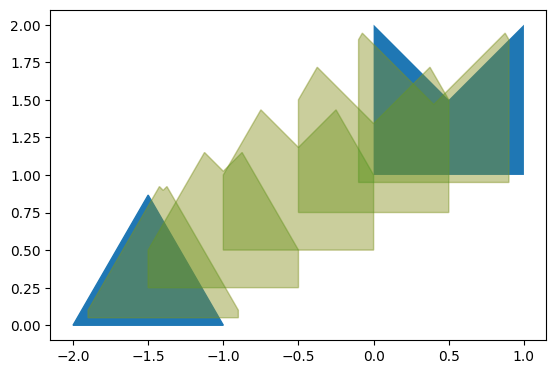

In [10]:
fig, ax = plt.subplots()

ax.fill(*shape1.T)
ax.fill(*shape2.T, color = "C0")

for w in (0.05, 0.25, 0.5, 0.75, 0.95):
    sumab = minkovski_sum(shape2, shape1, w)
    ax.fill(*sumab.T, alpha= 0.25, color="C1")

for w in (0.05, 0.25, 0.5, 0.75, 0.95):
    sumab = minkovski_sum(shape1, shape2, w)
    ax.fill(*sumab.T, alpha= 0.25, color="C2")
ax.set_aspect("equal")

In [11]:
p1 = np.loadtxt("./temp/Faux-Monnayeurs-outlet_2D.txt")
p2 =  np.loadtxt("./temp/Faux-Monnayeurs-inlet_2D.txt")

In [43]:
s1= np.vstack([p1[np.argmin(p1[:,1]):], p1[:np.argmin(p1[:,1])+1]])
s2 = np.vstack([p2[np.argmin(p2[:,1]):], p2[:np.argmin(p2[:,1])+1]])


In [44]:
P1 = Polygon()

In [45]:
s1.shape

(1140, 2)

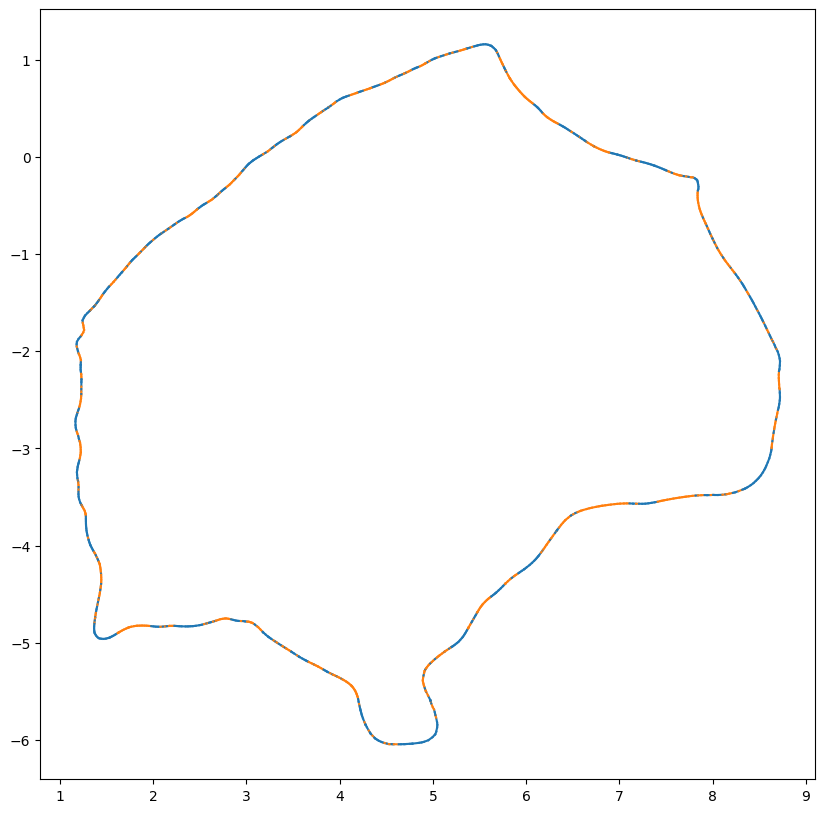

In [55]:
s1_vertices = np.diff(s1[::-1], axis=0)

fig, ax = plt.subplots(figsize=(10,10))


for i in range(len(s1_vertices)-1):
    if np.sign(np.cross(s1_vertices[i], s1_vertices[i+1])) > 0:

        ax.plot(*s1[len(s1)-i-2:len(s1)-i].T, color = "C0", ls="-")
    else:
        ax.plot(*s1[len(s1)-i-2:len(s1)-i].T, color = "C1", ls="-")


In [46]:
for p in s1[20:30]:
    P1.add_point(Vector(x=p[0], y=p[1]))

In [47]:
P1.convex_decompose(P1)

[Polygon [(4.28, -5.84), (4.29, -5.86), (4.31, -5.90), (4.23, -5.72), (4.24, -5.73), (4.24, -5.75), (4.25, -5.78), (4.27, -5.81), (4.28, -5.84)],
 Polygon [(4.28, -5.84), (4.28, -5.84), (4.28, -5.84)]]

In [ ]:
fig, ax = plt.subplots()


ax.fill(*s1.T)
ax.fill(*s2.T)

for w in (0.05, 0.25, 0.5, 0.75, 0.95):
    sumab = minkovski_sum(p1[::-1], p2[::-1], w)
    ax.fill(*sumab.T, alpha= 0.25, color="C2")

ax.set_aspect("equal")

In [ ]:
pip install poly_decomp